<a href="https://colab.research.google.com/github/zefilho1985/minera-o/blob/main/lp_stacking_corrigido.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Predição de proficiência em Língua Portuguesa

Coloque a planilha `LP.dados.turma(01) (3) (4)(3).xlsx` na mesma pasta de execução do notebook e execute as células em ordem. A Etapa 02 também aceita o nome original `LP.dados.turma(01).xlsx`.

A seleção do alpha usa apenas o treino. A arquitetura e os demais hiperparâmetros são fixos nesta execução. A média de validação do stacking é interna à seleção do alpha. A Etapa 21C reúne as métricas do mesmo modelo usado nas Etapas 22 a 25. A divisão é aleatória por turma, com escolas compartilhadas entre treino e teste.


In [1]:
%pip install numpy==2.4.6 pandas==2.2.3 scipy==1.16.3 matplotlib==3.10.0 seaborn==0.13.2 scikit-learn==1.6.1 xgboost==3.4.1 openpyxl==3.1.5 catboost==1.2.10 statsmodels==0.15.0 shap==0.54.1


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 46.0 MB/s  0:00:02


In [2]:
#etapa02
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from scipy.stats import kstest
# 1. Carregar os dados
from pathlib import Path

PLANILHA = Path("LP.dados.turma(01) (3) (4)(3).xlsx")
if not PLANILHA.is_file():
    PLANILHA = Path("LP.dados.turma(01).xlsx")
df = pd.read_excel(PLANILHA)

# 2. Limpar vírgulas, converter pra float, arredondar e finalmente pra int
for col in ['INICIAL', 'INTERMEDIARIO', 'FINAL', 'PROFICIENCIA']:
    df[col] = (
        df[col]
          .astype(str)                          # garante que é string
          .str.replace(',', '', regex=False)     # remove vírgulas (se houver)
          .astype(float)                         # converte pra float
          .round(0)                              # arredonda pra inteiro mais próximo
          .astype(int)                           # converte pra int
    )


In [3]:
#etapa03
from sklearn.model_selection import train_test_split
# 3. Definir X e y
X = df[['INICIAL', 'INTERMEDIARIO', 'FINAL']]
display(X)
y = df['PROFICIENCIA']
display(y)

# 4. Split 70/30
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42
)

print(f'Treino:  X_train={X_train.shape}, y_train={y_train.shape}')
print(f'Teste:   X_test={X_test.shape}, y_test={y_test.shape}')


,INICIAL,INTERMEDIARIO,FINAL
0,56,60,63
1,47,51,52
2,64,70,71
3,57,56,55
4,41,58,60
...,...,...,...
731,58,67,66
732,70,68,73
733,72,70,78
734,73,73,77


,PROFICIENCIA
0,258
1,211
2,271
3,250
4,230
...,...
731,260
732,274
733,280
734,275


Treino:  X_train=(515, 3), y_train=(515,)
Teste:   X_test=(221, 3), y_test=(221,)


,INICIAL,INTERMEDIARIO,FINAL,PROFICIENCIA
265,64,67,69,257
537,58,74,71,258
260,52,50,72,240
137,68,65,69,258
479,61,66,68,250
...,...,...,...,...
71,47,25,66,244
106,68,69,76,266
270,67,68,80,262
435,61,62,72,237


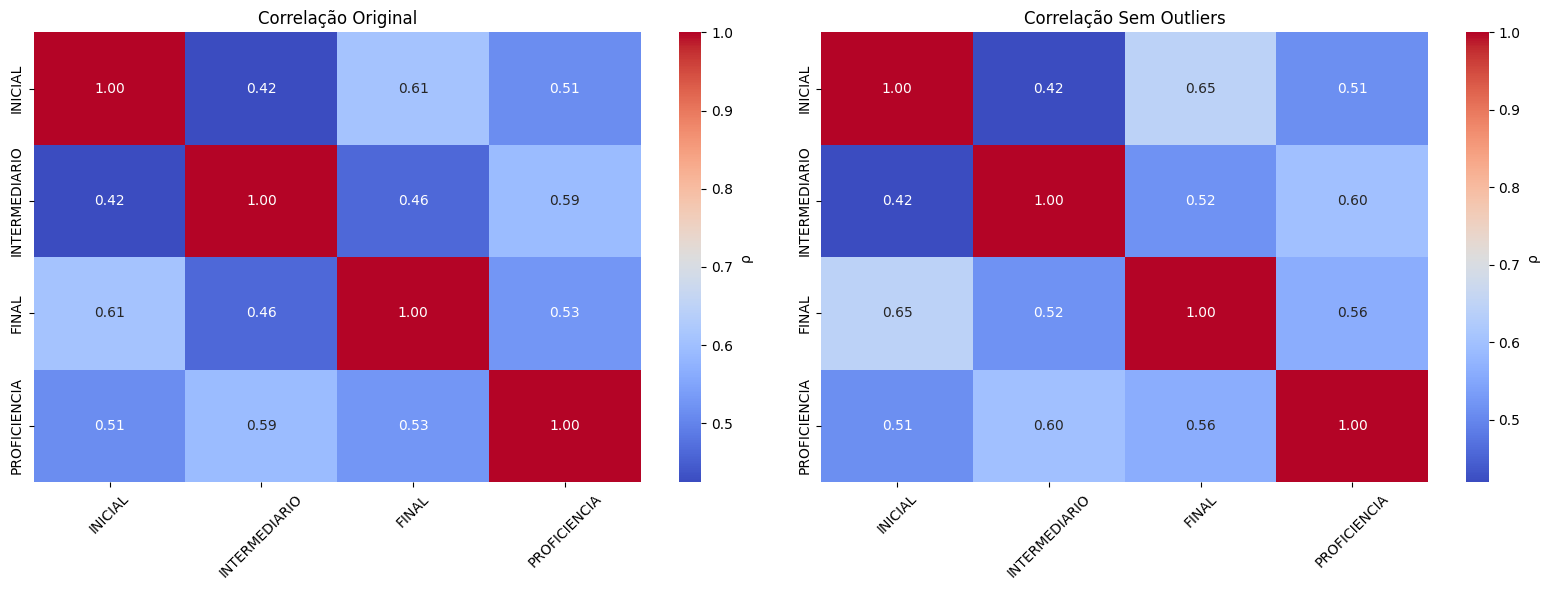

In [4]:
#ETAPA06
# 1. Reunir X_train e y_train
df_train = pd.concat([X_train, y_train], axis=1)
display(df_train)

# 2. Análise Exploratória e Tratamento de Outliers
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# 2.1 Matriz de correlação original
corr_orig = df_train.corr()

# 2.2 Remoção de outliers pelo método IQR
Q1 = df_train.quantile(0.25)
Q3 = df_train.quantile(0.75)
IQR = Q3 - Q1
mask = ~((df_train < (Q1 - 1.5 * IQR)) | (df_train > (Q3 + 1.5 * IQR))).any(axis=1)
df_clean = df_train[mask]

# 2.3 Matriz de correlação sem outliers
corr_clean = df_clean.corr()

# 2.4 Plotagem
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.heatmap(
    corr_orig,
    annot=True, fmt='.2f',
    cmap='coolwarm',
    cbar_kws={'label': 'ρ'},
    ax=axes[0]
)
axes[0].set_title('Correlação Original')
axes[0].tick_params(axis='x', rotation=45)

sns.heatmap(
    corr_clean,
    annot=True, fmt='.2f',
    cmap='coolwarm',
    cbar_kws={'label': 'ρ'},
    ax=axes[1]
)
axes[1].set_title('Correlação Sem Outliers')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()


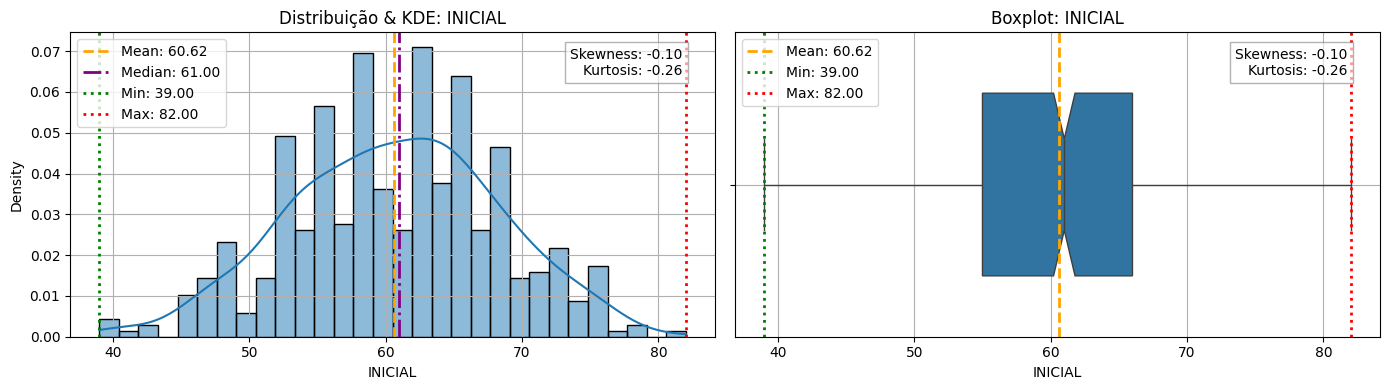

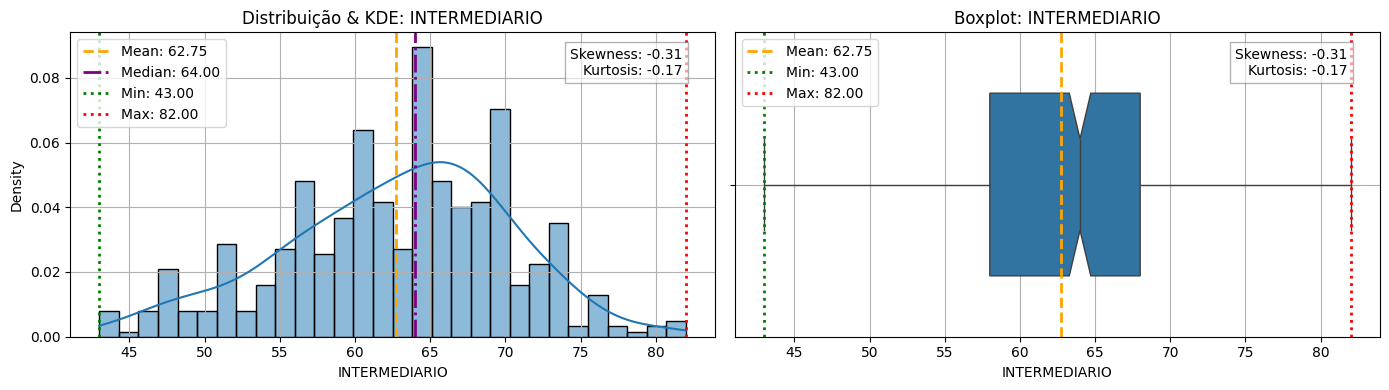

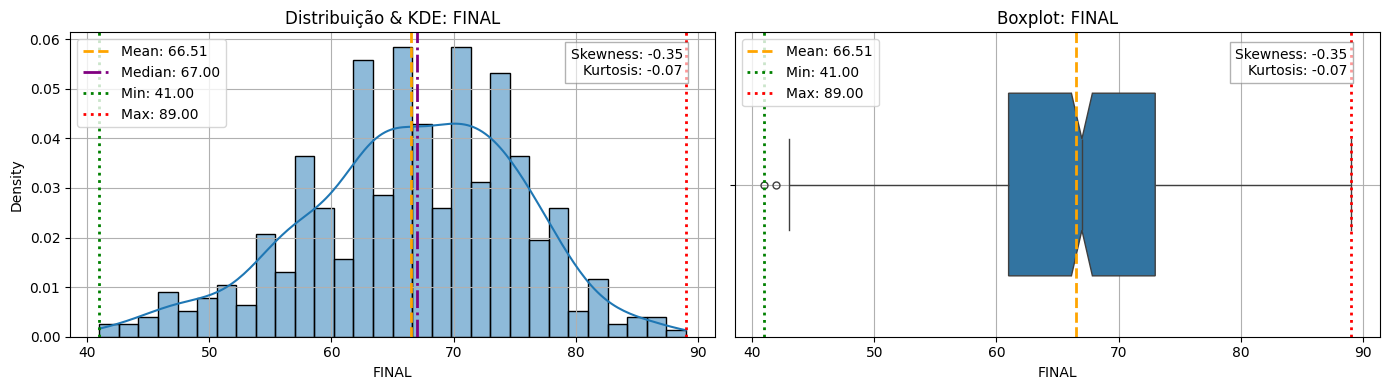

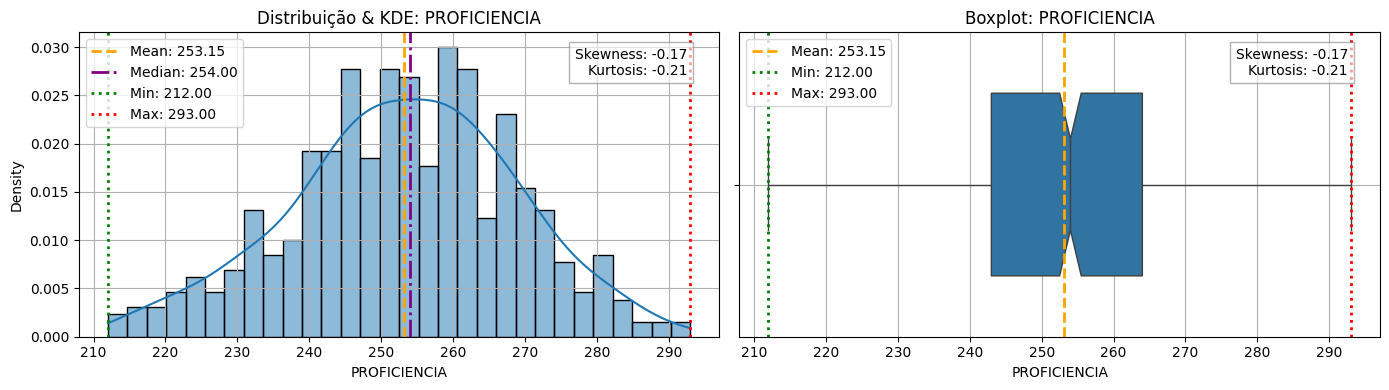

In [5]:
#ETAPA07
# 3. Estatísticas Descritivas aprimoradas
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt



for col in df_clean.columns:
    vals = df_clean[col]
    mean    = vals.mean()
    median  = vals.median()
    min_val = vals.min()
    max_val = vals.max()
    skew    = vals.skew()
    kurt    = vals.kurtosis()

    fig, (ax_hist, ax_box) = plt.subplots(1, 2, figsize=(14, 4))

    # --- Histograma + KDE ---
    sns.histplot(vals, bins=30, kde=True, stat='density', ax=ax_hist)
    ax_hist.axvline(mean,   color='orange', linestyle='--', linewidth=2, label=f'Mean: {mean:.2f}')
    ax_hist.axvline(median, color='purple', linestyle='-.', linewidth=2, label=f'Median: {median:.2f}')
    ax_hist.axvline(min_val, color='green', linestyle=':', linewidth=2, label=f'Min: {min_val:.2f}')
    ax_hist.axvline(max_val, color='red',   linestyle=':', linewidth=2, label=f'Max: {max_val:.2f}')
    ax_hist.text(
        0.95, 0.95,
        f'Skewness: {skew:.2f}\nKurtosis: {kurt:.2f}',
        transform=ax_hist.transAxes, ha='right', va='top',
        bbox=dict(facecolor='white', alpha=0.6, edgecolor='gray')
    )
    ax_hist.set_title(f'Distribuição & KDE: {col}')
    ax_hist.legend()
    ax_hist.grid(True)

    # --- Boxplot notch ---
    sns.boxplot(x=vals, notch=True, width=0.6, fliersize=5, ax=ax_box)
    ax_box.axvline(mean,   color='orange', linestyle='--', linewidth=2, label=f'Mean: {mean:.2f}')
    ax_box.axvline(min_val, color='green', linestyle=':', linewidth=2, label=f'Min: {min_val:.2f}')
    ax_box.axvline(max_val, color='red',   linestyle=':', linewidth=2, label=f'Max: {max_val:.2f}')
    ax_box.text(
        0.95, 0.95,
        f'Skewness: {skew:.2f}\nKurtosis: {kurt:.2f}',
        transform=ax_box.transAxes, ha='right', va='top',
        bbox=dict(facecolor='white', alpha=0.6, edgecolor='gray')
    )
    ax_box.set_title(f'Boxplot: {col}')
    ax_box.legend()
    ax_box.grid(True)

    plt.tight_layout()
    plt.show()


n original = 515 | n sem outliers = 481 | bootstrap: 2000 reamostragens


,r original,r sem outliers,Diferença,IC 95% Zou,Zou: significativa?,IC 95% bootstrap,p (bootstrap),Bootstrap: significativa?
Par,,,,,,,,
INICIAL × INTERMEDIARIO,0.425,0.420,-0.005,[-0.108; 0.097],não,[-0.060; 0.063],0.995,não
INICIAL × FINAL,0.608,0.645,0.038,[-0.038; 0.113],não,[-0.024; 0.079],0.254,não
INICIAL × PROFICIENCIA,0.514,0.513,-0.002,[-0.094; 0.090],não,[-0.058; 0.054],0.882,não
INTERMEDIARIO × FINAL,0.462,0.517,0.055,[-0.040; 0.149],não,[-0.010; 0.127],0.097,não
INTERMEDIARIO × PROFICIENCIA,0.593,0.598,0.005,[-0.076; 0.085],não,[-0.039; 0.058],0.668,não
FINAL × PROFICIENCIA,0.526,0.562,0.035,[-0.052; 0.123],não,[-0.036; 0.100],0.391,não


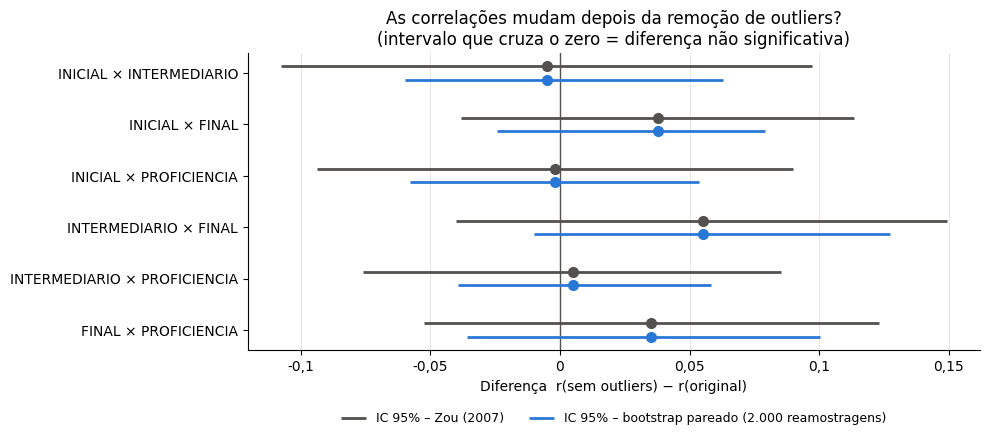

In [6]:
#ETAPA06B — Item 39 (Prof. João): o aumento das correlações depois do IQR é estatisticamente significativo?
# Método de Zou (2007) + bootstrap pareado. Usa df_train e df_clean criados na ETAPA06.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

def ic_fisher(r, n, nivel=0.95):
    """Intervalo de confiança do r de Pearson pela transformação z de Fisher."""
    z, ep = np.arctanh(r), 1 / np.sqrt(n - 3)
    q = stats.norm.ppf(1 - (1 - nivel) / 2)
    return np.tanh(z - q * ep), np.tanh(z + q * ep)

def zou_2007(r1, n1, r2, n2, nivel=0.95):
    """IC 95% para (r2 − r1) — Zou (2007), Psychological Methods 12(4), 399–413."""
    l1, u1 = ic_fisher(r1, n1, nivel)
    l2, u2 = ic_fisher(r2, n2, nivel)
    d = r2 - r1
    return d - np.sqrt((r2 - l2) ** 2 + (u1 - r1) ** 2), d + np.sqrt((u2 - r2) ** 2 + (r1 - l1) ** 2)

def remover_outliers_iqr(d):
    """Mesmo critério da ETAPA06: remove a turma se qualquer coluna estiver fora de [Q1 − 1,5·IQR; Q3 + 1,5·IQR]."""
    Q1, Q3 = d.quantile(0.25), d.quantile(0.75)
    IQR = Q3 - Q1
    fora = ((d < (Q1 - 1.5 * IQR)) | (d > (Q3 + 1.5 * IQR))).any(axis=1)
    return d[~fora.values]

variaveis = list(df_train.columns)
pares = [(a, b) for i, a in enumerate(variaveis) for b in variaveis[i + 1:]]

# Bootstrap pareado: sorteia 515 turmas com reposição, aplica o IQR na reamostra e mede a diferença
B, SEED = 2000, 42
rng = np.random.default_rng(SEED)
dif_boot = np.empty((B, len(pares)))
for i in range(B):
    amostra = df_train.iloc[rng.integers(0, len(df_train), len(df_train))]
    limpa = remover_outliers_iqr(amostra)
    dif_boot[i] = [limpa[a].corr(limpa[b]) - amostra[a].corr(amostra[b]) for a, b in pares]

linhas = []
for k, (a, b) in enumerate(pares):
    r1, r2 = df_train[a].corr(df_train[b]), df_clean[a].corr(df_clean[b])
    zi, zs = zou_2007(r1, len(df_train), r2, len(df_clean))
    bi, bs = np.percentile(dif_boot[:, k], [2.5, 97.5])
    p_boot = min(1.0, 2 * min((dif_boot[:, k] <= 0).mean(), (dif_boot[:, k] >= 0).mean()))
    linhas.append({'Par': f'{a} × {b}',
                   'r original': round(r1, 3), 'r sem outliers': round(r2, 3), 'Diferença': round(r2 - r1, 3),
                   'IC 95% Zou': f'[{zi:.3f}; {zs:.3f}]',
                   'Zou: significativa?': 'sim' if (zi > 0 or zs < 0) else 'não',
                   'IC 95% bootstrap': f'[{bi:.3f}; {bs:.3f}]', 'p (bootstrap)': round(p_boot, 3),
                   'Bootstrap: significativa?': 'sim' if (bi > 0 or bs < 0) else 'não',
                   '_zi': zi, '_zs': zs, '_bi': bi, '_bs': bs})
tab_zou = pd.DataFrame(linhas).set_index('Par')
print(f'n original = {len(df_train)} | n sem outliers = {len(df_clean)} | bootstrap: {B} reamostragens')
display(tab_zou.drop(columns=['_zi', '_zs', '_bi', '_bs']))

# Figura: diferença entre as correlações com os dois intervalos de confiança
CINZA, AZUL = '#52514e', '#2a78d6'
fig, ax = plt.subplots(figsize=(10, 4.6))
ypos = np.arange(len(tab_zou))[::-1]
ax.axvline(0, color=CINZA, lw=1)
ax.hlines(ypos + 0.13, tab_zou['_zi'], tab_zou['_zs'], color=CINZA, lw=2, label='IC 95% – Zou (2007)')
ax.hlines(ypos - 0.13, tab_zou['_bi'], tab_zou['_bs'], color=AZUL, lw=2,
          label='IC 95% – bootstrap pareado (2.000 reamostragens)')
ax.plot(tab_zou['Diferença'], ypos + 0.13, 'o', color=CINZA, ms=7)
ax.plot(tab_zou['Diferença'], ypos - 0.13, 'o', color=AZUL, ms=7)
ax.set_yticks(ypos)
ax.set_yticklabels(tab_zou.index)
ax.set_xlabel('Diferença  r(sem outliers) − r(original)')
ax.set_title('As correlações mudam depois da remoção de outliers?\n(intervalo que cruza o zero = diferença não significativa)')
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:g}'.replace('.', ',')))
ax.grid(axis='x', color='#e6e6e3')
ax.set_axisbelow(True)
for lado in ['top', 'right']:
    ax.spines[lado].set_visible(False)
ax.legend(frameon=False, loc='upper center', bbox_to_anchor=(0.5, -0.17), ncol=2, fontsize=9)
plt.tight_layout()
plt.show()

In [7]:
# ETAPA 21A — Definição da arquitetura do stacking
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from catboost import CatBoostRegressor
from sklearn.ensemble import RandomForestRegressor, StackingRegressor
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures, SplineTransformer, StandardScaler
from sklearn.svm import SVR
from xgboost import XGBRegressor

SEED = 42
ENTRADAS = ['INICIAL', 'INTERMEDIARIO', 'FINAL']
assert X_train.index.intersection(X_test.index).empty
assert X_train.index.equals(y_train.index)
assert X_test.index.equals(y_test.index)

def criar_stacking():
    return StackingRegressor([
        ('Random Forest', RandomForestRegressor(n_estimators=400, max_depth=8, min_samples_leaf=10, max_features=1.0,
                                                random_state=SEED, n_jobs=1)),
        ('XGBoost', XGBRegressor(n_estimators=500, max_depth=3, learning_rate=.05, subsample=.8, colsample_bytree=1.0,
                                 reg_lambda=10, min_child_weight=5, monotone_constraints='(1,1,1)',
                                 random_state=SEED, n_jobs=1)),
        ('CatBoost', CatBoostRegressor(iterations=800, depth=4, learning_rate=.05, l2_leaf_reg=5, subsample=.8,
                                       monotone_constraints='0:1,1:1,2:1', random_state=SEED, verbose=0, thread_count=1, allow_writing_files=False)),
        ('Spline + Ridge', Pipeline([('scaler', StandardScaler()), ('spline', SplineTransformer(n_knots=5, degree=3)),
                                     ('model', Ridge(alpha=1.0))])),
        ('Ridge polinomial', Pipeline([('poly', PolynomialFeatures(degree=2, include_bias=False)),
                                       ('scaler', StandardScaler()),
                                       ('kbest', SelectKBest(f_regression, k='all')), ('model', Ridge(alpha=1.0))])),
        ('SVR', Pipeline([('scaler', StandardScaler()), ('model', SVR(C=50, epsilon=2))]))],
        final_estimator=Ridge(alpha=1.0, positive=True), cv=5, passthrough=True, n_jobs=1)



In [8]:
# ETAPA 21B — Seleção do alpha usando somente as turmas de treino
kf = KFold(n_splits=5, shuffle=True, random_state=SEED)
busca_stacking = RandomizedSearchCV(
    estimator=criar_stacking(),
    param_distributions={'final_estimator__alpha': [0.1, 1.0, 10.0, 100.0]},
    n_iter=4,
    cv=kf,
    scoring='r2',
    n_jobs=1,
    random_state=SEED,
    refit=True,
    return_train_score=True,
    error_score='raise',
)
busca_stacking.fit(X_train, y_train)
stacking = busca_stacking.best_estimator_

selecao_alpha = pd.DataFrame(busca_stacking.cv_results_)[[
    'param_final_estimator__alpha', 'mean_train_score', 'mean_test_score',
    'std_test_score', 'rank_test_score',
]].rename(columns={
    'param_final_estimator__alpha': 'Alpha',
    'mean_train_score': 'R² médio — treino das dobras',
    'mean_test_score': 'R² médio — validação das dobras',
    'std_test_score': 'DP do R² de validação',
    'rank_test_score': 'Posição',
}).sort_values('Posição')
print(f"Alpha selecionado: {stacking.final_estimator_.alpha:g}")
display(selecao_alpha.round(8))


Alpha selecionado: 10


,Alpha,R² médio — treino das dobras,R² médio — validação das dobras,DP do R² de validação,Posição
2,10.0,0.573986,0.496673,0.042304,1
3,100.0,0.574594,0.496655,0.042894,2
1,1.0,0.573995,0.496653,0.042354,3
0,0.1,0.573995,0.496651,0.042359,4


 R² treino (CV)  R² validação (CV)    Gap  R² teste    MAE    RMSE  MAPE (%)
          0.574             0.4967 0.0773    0.5958 8.2293 10.3702    3.2937
Random Forest       0.00000
XGBoost             0.02812
CatBoost            0.12750
Spline + Ridge      0.36454
Ridge polinomial    0.00000
SVR                 0.34960
INICIAL             0.07037
INTERMEDIARIO       0.15030
FINAL               0.00000
Name: Coeficientes do Ridge, dtype: float64


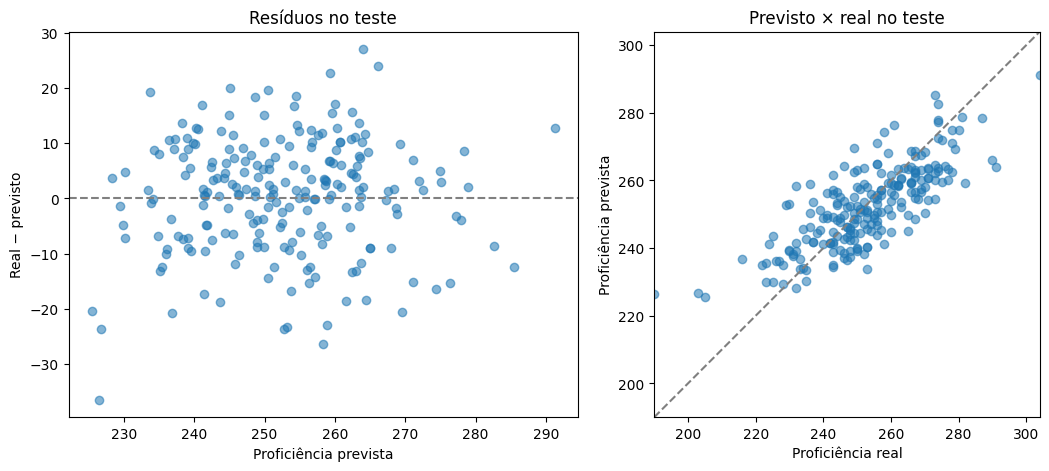

In [9]:
# ETAPA 21C — Avaliação do stacking selecionado nas turmas de teste
previsto = stacking.predict(X_test)
real = y_test.to_numpy()
residuos = real - previsto
r2_treino = busca_stacking.cv_results_["mean_train_score"][busca_stacking.best_index_]
r2_validacao = busca_stacking.best_score_

metricas = pd.DataFrame([{
    "R² treino (CV)": r2_treino,
    "R² validação (CV)": r2_validacao,
    "Gap": r2_treino - r2_validacao,
    "R² teste": r2_score(real, previsto),
    "MAE": mean_absolute_error(real, previsto),
    "RMSE": np.sqrt(mean_squared_error(real, previsto)),
    "MAPE (%)": 100 * np.mean(np.abs(residuos / real)) if np.all(real != 0) else np.nan,
}])
print(metricas.round(4).to_string(index=False))
nomes_meta = [nome for nome, _ in stacking.estimators] + ENTRADAS
print(pd.Series(stacking.final_estimator_.coef_, index=nomes_meta,
                name="Coeficientes do Ridge").round(5))

fig, (ax_res, ax_prev) = plt.subplots(1, 2, figsize=(11, 4.6), layout="constrained")
ax_res.scatter(previsto, residuos, alpha=0.55)
ax_res.axhline(0, linestyle="--", color="gray")
ax_res.set(title="Resíduos no teste", xlabel="Proficiência prevista", ylabel="Real − previsto")
limites = [min(real.min(), previsto.min()), max(real.max(), previsto.max())]
ax_prev.scatter(real, previsto, alpha=0.55)
ax_prev.plot(limites, limites, "--", color="gray")
ax_prev.set(
    title="Previsto × real no teste", xlabel="Proficiência real", ylabel="Proficiência prevista",
    xlim=limites, ylim=limites, aspect="equal",
)
plt.show()

### Diagnósticos da regressão linear (Etapas 04 e 05)

Os diagnósticos com as turmas de teste são executados após a seleção do stacking.

In [10]:
#ETAPA04
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.metrics import r2_score



# Regressão Linear
lr = LinearRegression().fit(X_train, y_train)
y_pred_lr = lr.predict(X_test)

rmse_lr = np.sqrt(mean_squared_error(y_test, y_pred_lr))
mae_lr  = mean_absolute_error(y_test, y_pred_lr)
r2_lr = r2_score(y_test, y_pred_lr)
mape_lr = (np.abs((y_test - y_pred_lr) / y_test)).mean() * 100

print(f'LinearRegression → R²={r2_lr:.3f}, MAE={mae_lr:.2f}, RMSE={rmse_lr:.2f}, MAPE={mape_lr:.2f}%')


LinearRegression → R²=0.529, MAE=8.82, RMSE=11.20, MAPE=3.54%


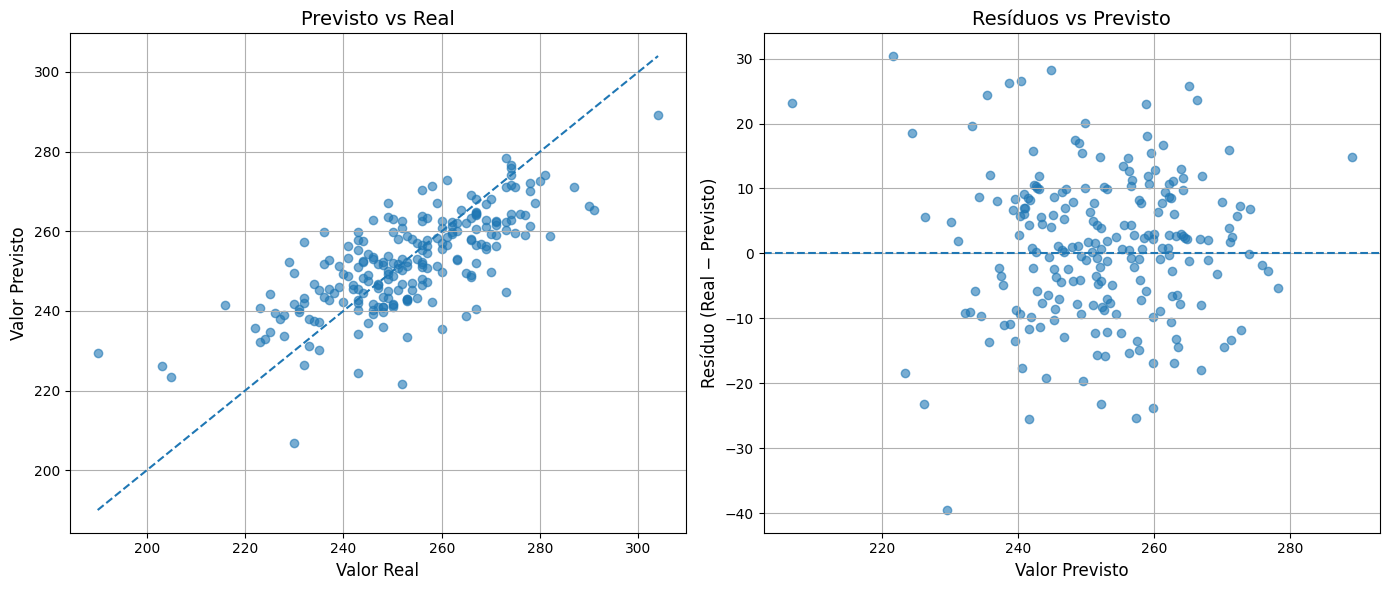

In [11]:
#ETAPA 05
import matplotlib.pyplot as plt

#Configura os subplots lado a lado
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
residuals = y_test - y_pred_lr
# --- Gráfico 1: Previsto vs Real ---
ax = axes[0]
ax.scatter(y_test, y_pred_lr, alpha=0.6)
ax.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], linestyle='--')
ax.set_xlabel('Valor Real', fontsize=12)
ax.set_ylabel('Valor Previsto', fontsize=12)
ax.set_title('Previsto vs Real', fontsize=14)
ax.grid(True)
ax.tick_params(axis='both', which='major', labelsize=10)

# --- Gráfico 2: Resíduos vs Previsto ---
ax = axes[1]
ax.scatter(y_pred_lr, residuals, alpha=0.6)
ax.axhline(0, linestyle='--')
ax.set_xlabel('Valor Previsto', fontsize=12)
ax.set_ylabel('Resíduo (Real − Previsto)', fontsize=12)
ax.set_title('Resíduos vs Previsto', fontsize=14)
ax.grid(True)
ax.tick_params(axis='both', which='major', labelsize=10)

plt.tight_layout()
plt.show()


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (2000) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (2000) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (2000) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (2000) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perce

▶ Regressão Linear
▶ MLP Regressor
▶ Random Forest
▶ XGBoost
▶ CatBoost


,R² treino (CV),R² validação (CV),Gap treino–validação,R² teste,MAE,RMSE,MAPE (%)
Modelo,,,,,,,
Stacking (RF + XGBoost + CatBoost + Spline + Ridge polinomial + SVR → Ridge),0.5740,0.4967,0.0773,0.5958,8.2293,10.3702,3.2937
CatBoost,0.5866,0.4864,0.1002,0.5843,8.3667,10.5166,3.3478
XGBoost,0.6169,0.4709,0.1460,0.5740,8.4385,10.6462,3.3773
Random Forest,0.5983,0.4823,0.1160,0.5687,8.4871,10.7125,3.3947
Regressão Linear,0.4626,0.4399,0.0227,0.5286,8.8231,11.1997,3.5363
MLP Regressor,0.5127,0.4620,0.0507,0.5234,8.6787,11.2618,3.4801


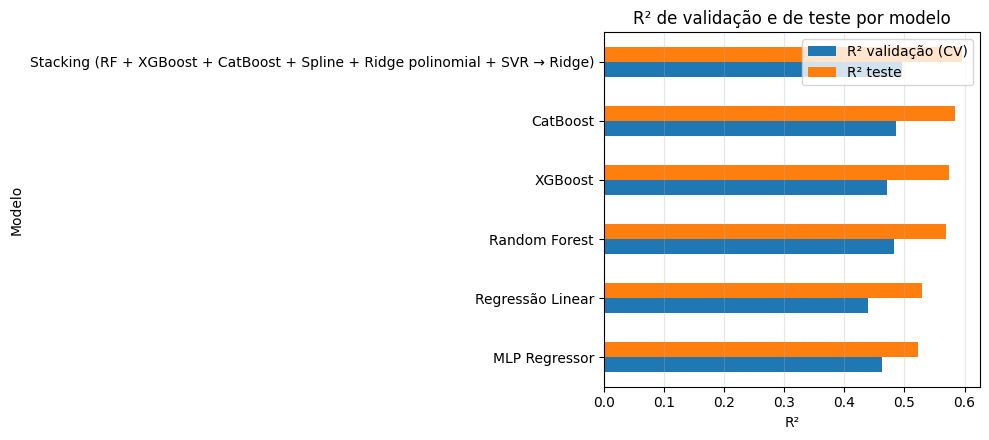

In [12]:
# ETAPA 22 — Comparativo do stacking com os algoritmos da dissertação
# Mesmo protocolo para todos: treino com as 515 turmas (X_train), validação cruzada K-Fold (k=5, embaralhada, seed 42)
# para R² treino, R² validação e gap, e avaliação final nas 221 turmas de teste (X_test).
# Usa metricas da ETAPA 21C, calculadas com o stacking escolhido na ETAPA 21B.
import numpy as np, pandas as pd
from sklearn.model_selection import KFold, cross_validate, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.linear_model import LinearRegression
from sklearn.neural_network import MLPRegressor
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from catboost import CatBoostRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

kf = KFold(n_splits=5, shuffle=True, random_state=SEED)

def avaliar(nome, modelo):
    cv = cross_validate(modelo, X_train, y_train, cv=kf, scoring='r2', return_train_score=True, n_jobs=1)
    tr, va = cv['train_score'].mean(), cv['test_score'].mean()
    p = modelo.fit(X_train, y_train).predict(X_test)
    return {'Modelo': nome, 'R² treino (CV)': tr, 'R² validação (CV)': va, 'Gap treino–validação': tr - va,
            'R² teste': r2_score(y_test, p), 'MAE': mean_absolute_error(y_test, p),
            'RMSE': np.sqrt(mean_squared_error(y_test, p)), 'MAPE (%)': np.mean(np.abs((y_test - p) / y_test)) * 100}

def pp(m):   # padronização + seleção de atributos, como na dissertação
    return Pipeline([('scaler', StandardScaler()), ('kbest', SelectKBest(f_regression, k='all')), ('model', m)])

def busca(est, grade):   # RandomizedSearchCV com 20 combinações, escolhidas pelo R² de validação cruzada
    return RandomizedSearchCV(est, grade, n_iter=20, cv=kf, scoring='r2', n_jobs=1,
                              random_state=SEED).fit(X_train, y_train).best_estimator_

modelos = {
    'Regressão Linear': pp(LinearRegression()),
    'MLP Regressor': busca(pp(MLPRegressor(random_state=SEED, max_iter=2000)),
        {'model__hidden_layer_sizes': [(50,), (100,), (50, 50)], 'model__activation': ['relu', 'tanh'],
         'model__alpha': [1e-4, 1e-3, 1e-2], 'model__learning_rate_init': [.001, .01]}),
    'Random Forest': busca(pp(RandomForestRegressor(random_state=SEED)),
        {'model__n_estimators': [200, 400, 800], 'model__max_depth': [5, 10, 15],
         'model__min_samples_leaf': [2, 5, 10], 'model__max_features': ['sqrt', .5]}),
    'XGBoost': busca(pp(XGBRegressor(objective='reg:squarederror', random_state=SEED, n_jobs=1)),
        {'model__n_estimators': [200, 400, 800], 'model__max_depth': [3, 4, 5], 'model__learning_rate': [.01, .05, .1],
         'model__subsample': [.6, .8, 1.], 'model__colsample_bytree': [.6, .8, 1.],
         'model__reg_alpha': [0, .1, 1], 'model__reg_lambda': [1, 5, 10]}),
    'CatBoost': busca(pp(CatBoostRegressor(verbose=0, thread_count=1, random_state=SEED, allow_writing_files=False)),
        {'model__iterations': [200, 400, 800], 'model__depth': [4, 6, 8], 'model__learning_rate': [.01, .05, .1],
         'model__l2_leaf_reg': [1, 3, 5], 'model__subsample': [.6, .8, 1.], 'model__rsm': [.6, .8, 1.]}),
}
linhas = []
for nome, m in modelos.items():
    print('▶', nome); linhas.append(avaliar(nome, m))
linhas.append({'Modelo': 'Stacking (RF + XGBoost + CatBoost + Spline + Ridge polinomial + SVR → Ridge)',
               **metricas.rename(columns={'Gap': 'Gap treino–validação'}).iloc[0].to_dict()})   # resultado da ETAPA 21

comparativo = pd.DataFrame(linhas).set_index('Modelo').sort_values('R² teste', ascending=False)
display(comparativo.round(4))

ax = comparativo[['R² validação (CV)', 'R² teste']].iloc[::-1].plot.barh(figsize=(10, 4.5))
ax.set(title='R² de validação e de teste por modelo', xlabel='R²'); ax.grid(axis='x', alpha=.3)
plt.tight_layout(); plt.show()


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-p

,|SHAP| médio (pontos de proficiência),IC 95% inferior,IC 95% superior,SHAP mínimo,SHAP máximo,Peso relativo (%)
INTERMEDIARIO,5.641,5.153,6.121,-11.319,16.668,49.289
INICIAL,3.157,2.840,3.481,-9.157,14.000,27.589
FINAL,2.646,2.375,2.922,-7.731,9.289,23.121


,Diferença média de |SHAP|,p-valor (Wilcoxon pareado),"Significativo (α = 0,05)?"
Comparação,,,
INTERMEDIARIO × INICIAL,2.483,1.912728e-18,sim
INTERMEDIARIO × FINAL,2.995,3.325508e-23,sim


Avaliação de maior peso na proficiência prevista: INTERMEDIARIO (49.3% do total de SHAP)


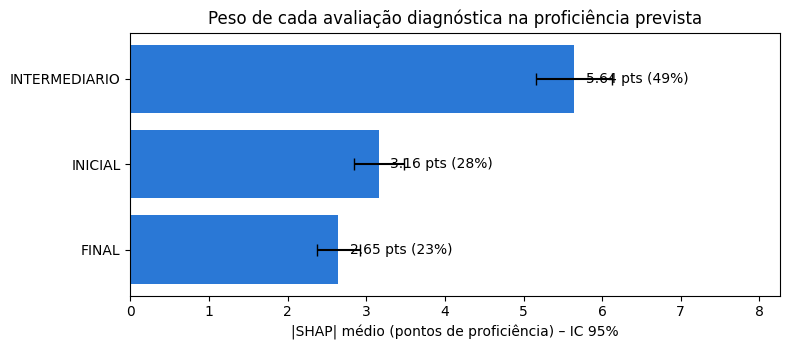

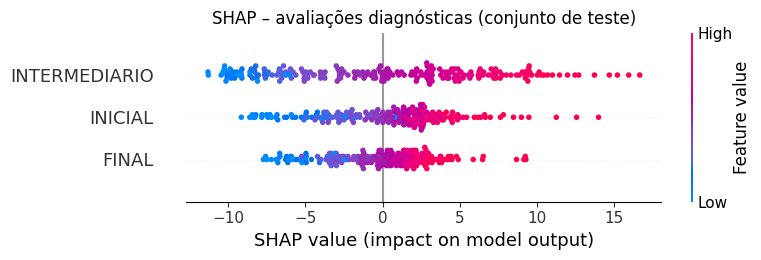

In [13]:
# ETAPA 23 — SHAP: peso de cada avaliação (INICIAL, INTERMEDIÁRIA, FINAL) na proficiência prevista
# KernelExplainer sobre o stacking completo: o valor SHAP diz quantos pontos de proficiência cada avaliação
# acrescenta ou retira da previsão de cada turma do teste, em relação à previsão média.
import shap
from scipy import stats

fundo = X_train.sample(100, random_state=SEED)                    # amostra de referência
explicador = shap.KernelExplainer(stacking.predict, fundo)
shap_aval = explicador.shap_values(X_test, silent=True)           # matriz 221 turmas × 3 avaliações
abs_shap = pd.DataFrame(np.abs(shap_aval), columns=ENTRADAS, index=X_test.index)

# Quantidade de SHAP por avaliação, com IC 95% por bootstrap
rng = np.random.default_rng(SEED)
boot = np.array([abs_shap.iloc[rng.integers(0, len(abs_shap), len(abs_shap))].mean().values for _ in range(2000)])
peso = pd.DataFrame({'|SHAP| médio (pontos de proficiência)': abs_shap.mean(),
                     'IC 95% inferior': np.percentile(boot, 2.5, axis=0),
                     'IC 95% superior': np.percentile(boot, 97.5, axis=0),
                     'SHAP mínimo': shap_aval.min(0), 'SHAP máximo': shap_aval.max(0)}, index=ENTRADAS)
peso['Peso relativo (%)'] = 100 * peso.iloc[:, 0] / peso.iloc[:, 0].sum()
peso = peso.sort_values('|SHAP| médio (pontos de proficiência)', ascending=False)
display(peso.round(3))

# Prova estatística: a avaliação de maior peso tem |SHAP| maior que as outras? (Wilcoxon pareado, turma a turma)
maior = peso.index[0]
testes = pd.DataFrame([{'Comparação': f'{maior} × {v}',
                        'Diferença média de |SHAP|': (abs_shap[maior] - abs_shap[v]).mean(),
                        'p-valor (Wilcoxon pareado)': stats.wilcoxon(abs_shap[maior], abs_shap[v]).pvalue}
                       for v in peso.index[1:]]).set_index('Comparação')
testes['Significativo (α = 0,05)?'] = np.where(testes['p-valor (Wilcoxon pareado)'] < .05, 'sim', 'não')
display(testes.round({'Diferença média de |SHAP|': 3}))
print(f'Avaliação de maior peso na proficiência prevista: {maior} '
      f'({peso.loc[maior, "Peso relativo (%)"]:.1f}% do total de SHAP)')

# Gráficos: barras com a quantidade de SHAP e enxame (beeswarm)
fig, ax = plt.subplots(figsize=(8, 3.6))
y_pos = np.arange(len(peso))[::-1]
ax.barh(y_pos, peso.iloc[:, 0], xerr=[peso.iloc[:, 0] - peso['IC 95% inferior'], peso['IC 95% superior'] - peso.iloc[:, 0]],
        capsize=4, color='#2a78d6')
for yy, v, pct in zip(y_pos, peso.iloc[:, 0], peso['Peso relativo (%)']):
    ax.text(v + .15, yy, f'{v:.2f} pts ({pct:.0f}%)', va='center')
ax.set_yticks(y_pos, peso.index); ax.set_xlabel('|SHAP| médio (pontos de proficiência) – IC 95%')
ax.set_title('Peso de cada avaliação diagnóstica na proficiência prevista'); ax.set_xlim(0, peso['IC 95% superior'].max() * 1.35)
plt.tight_layout(); plt.show()

shap.summary_plot(shap_aval, X_test, show=False)
plt.title('SHAP – avaliações diagnósticas (conjunto de teste)'); plt.tight_layout(); plt.show()


,Peso no Ridge (coeficiente),|SHAP| médio (pontos de proficiência),Participação no SHAP (%),Tipo
Spline + Ridge,0.3645,3.4990,35.5453,modelo-base
SVR,0.3496,3.3626,34.1599,modelo-base
CatBoost,0.1275,1.2316,12.5111,modelo-base
INTERMEDIARIO (nota original),0.1503,1.0038,10.1971,nota original (passthrough)
INICIAL (nota original),0.0704,0.4530,4.6014,nota original (passthrough)
XGBoost,0.0281,0.2939,2.9852,modelo-base
Random Forest,0.0000,0.0000,0.0000,modelo-base
Ridge polinomial,0.0000,0.0000,0.0000,modelo-base
FINAL (nota original),0.0000,0.0000,0.0000,nota original (passthrough)


Participação dos modelos-base no SHAP do meta-modelo: 85.2% | notas originais: 14.8%


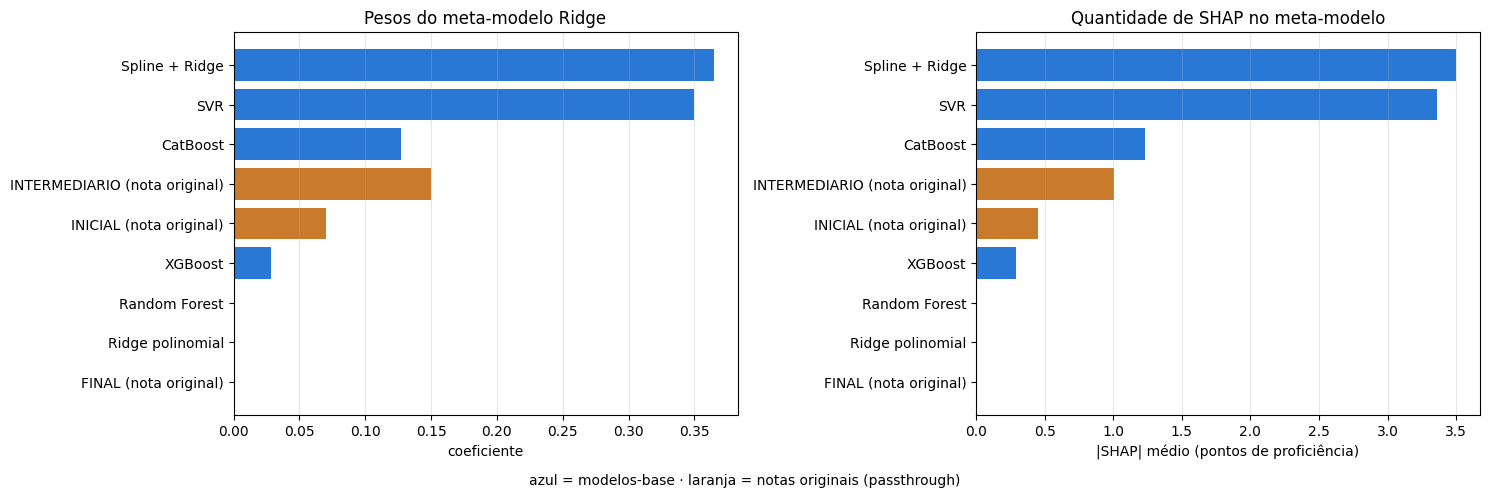

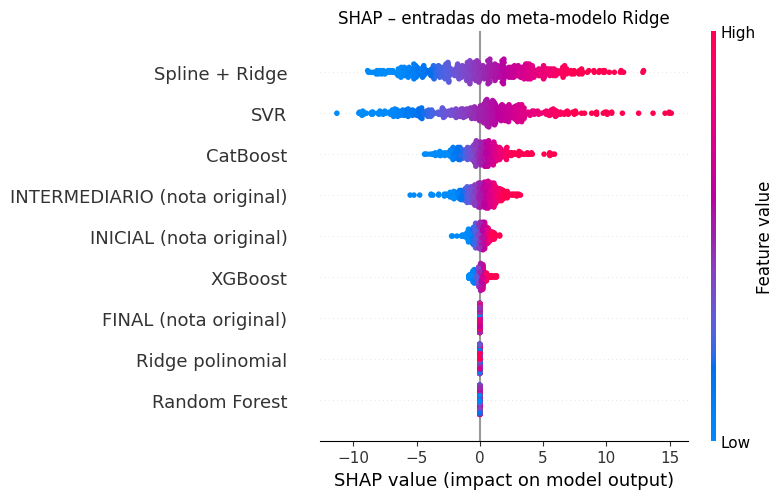

In [14]:
# ETAPA 24 — SHAP do meta-modelo: peso de cada algoritmo do stacking
# O meta-modelo Ridge recebe as previsões dos 6 modelos-base e, com passthrough=True, também as 3 notas originais.
# Mostram-se (a) os coeficientes (pesos) do Ridge e (b) a quantidade de SHAP de cada entrada (KernelExplainer).
bases = dict(zip([n for n, _ in stacking.estimators], stacking.estimators_))
X_meta = pd.concat([pd.DataFrame({n: m.predict(X_train) for n, m in bases.items()}, index=X_train.index), X_train], axis=1)
X_meta.columns = list(bases) + [f'{c} (nota original)' for c in ENTRADAS]

explicador_meta = shap.KernelExplainer(stacking.final_estimator_.predict, X_meta.sample(100, random_state=SEED))
shap_meta = explicador_meta.shap_values(X_meta, silent=True)

pesos = pd.DataFrame({'Peso no Ridge (coeficiente)': stacking.final_estimator_.coef_,
                      '|SHAP| médio (pontos de proficiência)': np.abs(shap_meta).mean(0)}, index=X_meta.columns)
pesos['Participação no SHAP (%)'] = 100 * pesos.iloc[:, 1] / pesos.iloc[:, 1].sum()
pesos['Tipo'] = ['modelo-base'] * len(bases) + ['nota original (passthrough)'] * len(ENTRADAS)
pesos = pesos.sort_values('|SHAP| médio (pontos de proficiência)', ascending=False)
display(pesos.round(4))
print('Participação dos modelos-base no SHAP do meta-modelo: '
      f'{pesos.loc[pesos.Tipo == "modelo-base", "Participação no SHAP (%)"].sum():.1f}% | '
      f'notas originais: {pesos.loc[pesos.Tipo != "modelo-base", "Participação no SHAP (%)"].sum():.1f}%')

fig, ax = plt.subplots(1, 2, figsize=(15, 4.8))
pp_ = pesos.iloc[::-1]
cores = ['#2a78d6' if t == 'modelo-base' else '#c97a2b' for t in pp_.Tipo]
ax[0].barh(pp_.index, pp_['Peso no Ridge (coeficiente)'], color=cores)
ax[0].set(title='Pesos do meta-modelo Ridge', xlabel='coeficiente')
ax[1].barh(pp_.index, pp_['|SHAP| médio (pontos de proficiência)'], color=cores)
ax[1].set(title='Quantidade de SHAP no meta-modelo', xlabel='|SHAP| médio (pontos de proficiência)')
for a in ax: a.grid(axis='x', alpha=.3)
fig.text(.5, -.02, 'azul = modelos-base · laranja = notas originais (passthrough)', ha='center')
plt.tight_layout(); plt.show()

shap.summary_plot(shap_meta, X_meta, show=False)
plt.title('SHAP – entradas do meta-modelo Ridge'); plt.tight_layout(); plt.show()


Estatísticas do ganho previsto de proficiência (uplift) – 55%–60% na INTERMEDIÁRIA, +10 p.p.


,Valor
Número de turmas (n),47
Média,9.695
Mediana,9.315
Desvio padrão (DP),2.200
Mínimo,5.174
1º Quartil (Q1),8.281
3º Quartil (Q3),10.824
Máximo,15.901
IC 95% da média,[9.049 ; 10.341]
IC 95% da mediana (bootstrap),[8.710 ; 9.944]


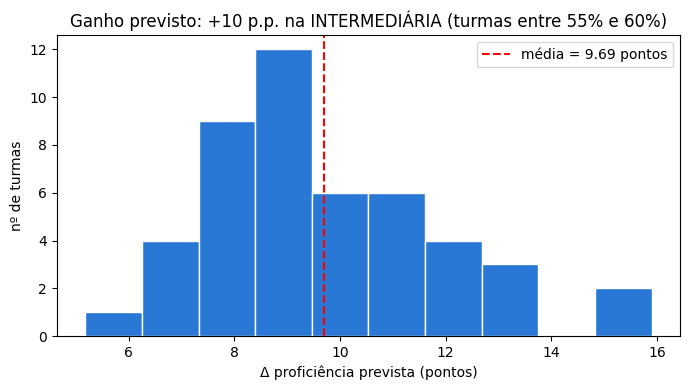

,INICIAL,INTERMEDIARIO,FINAL,Proficiência prevista,Δ previsto (+10 p.p.)
356,66,57,52,241.48,15.90
486,73,59,53,245.41,15.59
296,66,58,63,246.95,13.22
33,67,60,63,249.71,13.22
6,40,58,74,240.47,12.81
473,69,58,65,248.91,12.16
139,67,58,65,248.68,12.15
583,45,59,55,236.05,11.95
344,60,56,59,242.59,11.75
443,58,55,54,239.13,11.13


,Número de turmas (n),Média,Mediana,Desvio padrão (DP),IC 95% da média,IC 95% da mediana (bootstrap)
INICIAL,53,3.059,2.233,3.748,[2.025 ; 4.092],[1.170 ; 3.364]
INTERMEDIARIO,47,9.695,9.315,2.200,[9.049 ; 10.341],[8.710 ; 9.944]
FINAL,38,4.032,3.962,1.982,[3.380 ; 4.683],[3.394 ; 4.613]


In [15]:
# ETAPA 25 — Simulação contrafactual: +10 p.p. na avaliação INTERMEDIÁRIA (turmas entre 55% e 60%)
# Algoritmo 2 da dissertação, no conjunto de teste. INICIAL e FINAL ficam constantes.
# Δ = ŷ_novo − ŷ_original é o ganho que o MODELO prevê; não é o efeito causal de uma intervenção pedagógica.
def contrafactual(var='INTERMEDIARIO', faixa=(55, 60), incremento=10, B=5000):
    S = X_test[(X_test[var] >= faixa[0]) & (X_test[var] <= faixa[1])]
    if len(S) == 0:
        return None, None
    S_novo = S.copy(); S_novo[var] = np.minimum(100, S_novo[var] + incremento)
    delta = pd.Series(stacking.predict(S_novo) - stacking.predict(S), index=S.index)
    n, media, dp = len(delta), delta.mean(), delta.std(ddof=1)
    ic_media = stats.t.interval(.95, n - 1, loc=media, scale=dp / np.sqrt(n))
    rng = np.random.default_rng(SEED)
    ic_mediana = np.percentile([np.median(rng.choice(delta.values, n, replace=True)) for _ in range(B)], [2.5, 97.5])
    resumo = pd.Series({'Número de turmas (n)': n, 'Média': media, 'Mediana': delta.median(), 'Desvio padrão (DP)': dp,
                        'Mínimo': delta.min(), '1º Quartil (Q1)': delta.quantile(.25), '3º Quartil (Q3)': delta.quantile(.75),
                        'Máximo': delta.max(),
                        'IC 95% da média': f'[{ic_media[0]:.3f} ; {ic_media[1]:.3f}]',
                        'IC 95% da mediana (bootstrap)': f'[{ic_mediana[0]:.3f} ; {ic_mediana[1]:.3f}]'})
    return resumo, delta

fmt = lambda v: f'{v:.3f}' if isinstance(v, float) else v
resumo, delta = contrafactual('INTERMEDIARIO')
print('Estatísticas do ganho previsto de proficiência (uplift) – 55%–60% na INTERMEDIÁRIA, +10 p.p.')
display(resumo.map(fmt).to_frame('Valor'))

plt.figure(figsize=(7, 4)); plt.hist(delta, bins=10, edgecolor='white', color='#2a78d6')
plt.axvline(delta.mean(), color='red', ls='--', label=f'média = {delta.mean():.2f} pontos')
plt.xlabel('Δ proficiência prevista (pontos)'); plt.ylabel('nº de turmas')
plt.title('Ganho previsto: +10 p.p. na INTERMEDIÁRIA (turmas entre 55% e 60%)'); plt.legend()
plt.tight_layout(); plt.show()

detalhe = X_test.loc[delta.index].assign(**{'Proficiência prevista': stacking.predict(X_test.loc[delta.index]),
                                             'Δ previsto (+10 p.p.)': delta})
display(detalhe.sort_values('Δ previsto (+10 p.p.)', ascending=False).round(2))

# Mesmo exercício em cada avaliação, para comparar onde o ganho previsto é maior
comparacao = pd.DataFrame({v: contrafactual(v)[0] for v in ENTRADAS}).T
display(comparacao[['Número de turmas (n)', 'Média', 'Mediana', 'Desvio padrão (DP)',
                    'IC 95% da média', 'IC 95% da mediana (bootstrap)']].map(fmt))
